In [12]:
from skyfield.api import load, wgs84, Topos
import numpy as np
from datetime import datetime, timedelta
import pytz
from tqdm import tqdm
from matplotlib import pyplot as plt
from scipy.optimize import minimize
import satfunc

In [13]:
from sys import platform
if platform == "linux" or platform == "linux2":
    # path = '/home/jidazhang/Desktop/starlink_ofdm/AoA_Sim/tles/10_31/STARLINK-6150.tle'
    path = '/home/jidazhang/Desktop/starlink_ofdm/AoA_Sim/tles/11_5/STARLINK-5718.tle'
elif platform == "win32":
    path = 'D:\\Desktop\\study\\2023_summer\\starlink_ofdm\\AoA_Sim\\tles\\10_31\\STARLINK-6150.tle'
else:
    path = '/Users/ishani/UIUC/Research/starlink_ofdm/AoA_Sim/tles/10_31/STARLINK-6150.tle'

satellites = load.tle_file(path)
lat, lon = +40.11389690596162, -88.22484814695467
lnb = wgs84.latlon(lat, lon)
# start_time = datetime(2023, 10, 31, 0, 0, 0, tzinfo=pytz.UTC)+timedelta(hours=5)
# stop_time = datetime(2023, 10, 31, 0, 1, 0, tzinfo=pytz.UTC)+timedelta(hours=5)
start_time = datetime(2023, 11, 5, 0, 0, 0, tzinfo=pytz.UTC)+timedelta(hours=5) 
stop_time = datetime(2023, 11, 5, 0, 1, 0, tzinfo=pytz.UTC)+timedelta(hours=5)

In [14]:
fs = 10
fc = 11.575e9
# generate ground truth doppler shift
t_list, doppler_shift = satfunc.calc_doppler(satellites[0], lnb, start_time, stop_time, fs, fc)

# Function to calculate the difference between observed and calculated doppler shift
def difference(params, satellite, gt_doppler, start_time, stop_time):
    _, doppler_shift = satfunc.calc_doppler(satellite, wgs84.latlon(params[0], params[1]), start_time, stop_time, fs, fc)
    return np.linalg.norm(doppler_shift - gt_doppler)

# Initial guess for observer's latitude and longitude
initial_guess = [lat-1, lon+1]
bounds = [(-90, 90), (-180, 180)]

# Optimize to find the observer's latitude and longitude
result = minimize(difference, initial_guess, args=(satellites[0], doppler_shift, start_time, stop_time), method='L-BFGS-B', bounds=bounds)

# Extract the optimized latitude and longitude
optimized_latitude, optimized_longitude = result.x

print(f"Observer's Latitude: {optimized_latitude}, Observer's Longitude: {optimized_longitude}")

Observer's Latitude: 40.11389693895712, Observer's Longitude: -88.22484816042595


In [16]:
print(f'Localization Error = {satfunc.calc_distance(lon,lat,optimized_longitude,optimized_latitude):.2f} meters')

Localization Error = 0.00 meters


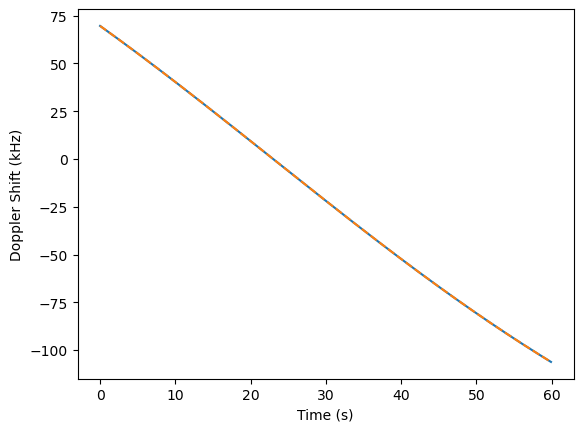

In [17]:
_, dopp_estimated = satfunc.calc_doppler(satellites[0], wgs84.latlon(optimized_latitude, optimized_longitude), start_time, stop_time, fs, fc)
plt.plot(t_list, doppler_shift/1e3)
plt.plot(t_list, dopp_estimated/1e3, '--')
plt.xlabel('Time (s)')
plt.ylabel('Doppler Shift (kHz)')
plt.show()